In [2]:
%pip install numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

Initialization Values


In [4]:
sigma = 3.40 # in Å
epsilon = 0.0104 # in ev
x0 = 3.808 #in Å 
dt = 0.001 #in ps
n = 100000
m0 = (39.948/6.023)*10**-26 #in Kg

For the particle to oscillate, Total Energy must be negative

E = KE + PE < 0 => KE < -PE 

KE = (m*v**2)/2 = epsilon

v < sqrt(epsilon*2/m)

v < 224m/s

as x and dt are in Angstrom and picoseconds v< 2.2 Å /ps

assuming v0 = 2 Å /ps


In [5]:
v0 = 2

In [6]:
#calcuating the potential energy of the particle in eV
def PE(x,sigma = sigma , epsilon = epsilon):
    return 4*epsilon*( ((sigma/x)**12) - ((sigma/x)**6))

In [7]:
#calculating force at the particle in eV/Å
def force(x,sigma = sigma , epsilon = epsilon): 
    return 4*epsilon*((((12*sigma**12)/(x**13)))-(((6*sigma**6)/(x**7))))


In [8]:
#acceleration of particle 
def acc(x, m = m0):
    return (force(x)*1.602*10**(-23))/m

In [9]:
#Kinetic Energy of particle
def KE(v, m=m0):
    return ((m*v**2)*10**23)/(2*1.602)

In [10]:
np.sqrt((-2*PE(x0)*1.6*10**(-19))/m0)

np.float64(223.98161565851973)

Verlet Algorithm

In [11]:
x = np.zeros(n+1 ,dtype=float) 
v = np.zeros(n ,dtype=float)
a = np.zeros(n+1 ,dtype=float)

x[0] = x0
x[1] = x0 + v0*dt
v[0] = v0
a[0] = acc(x[0])
a[1] = acc(x[1])

In [12]:
for i in range(2,n+1):
    x[i] = 2*(x[i-1]) + a[i-1]*dt*dt - x[i-2]
    v[i-1] = (x[i] - x[i-2])/(2*dt)
    a[i] = acc(x[i])
x

array([3.808     , 3.81      , 3.81200008, ..., 5.28243506, 5.28298604,
       5.28353632], shape=(100001,))

In [13]:
x = x[:-1]

Plotting the Graph

In [14]:
F = force(x)
U = PE(x)

Potential Energy VS X plot

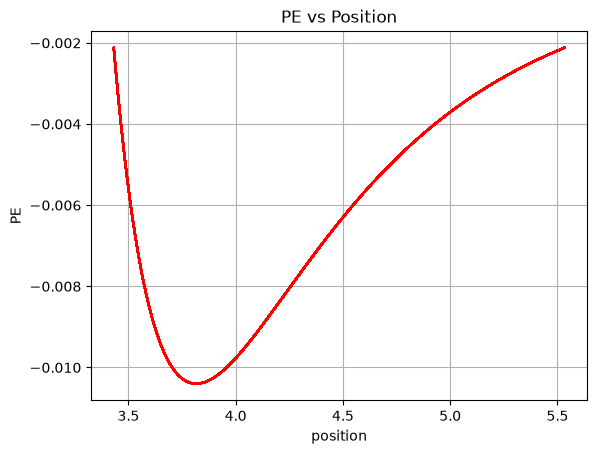

In [15]:
plt.plot(x,U, color='red')
plt.grid()
plt.title("PE vs Position")
plt.xlabel('position')
plt.ylabel('PE')
plt.show()

In [16]:
minPE = np.argmin(U)
min = x[minPE]

print("The minimum of the potential energy is obtained at x = ", min, "Å")

The minimum of the potential energy is obtained at x =  3.8163695250969516 Å


Force VS X Plot

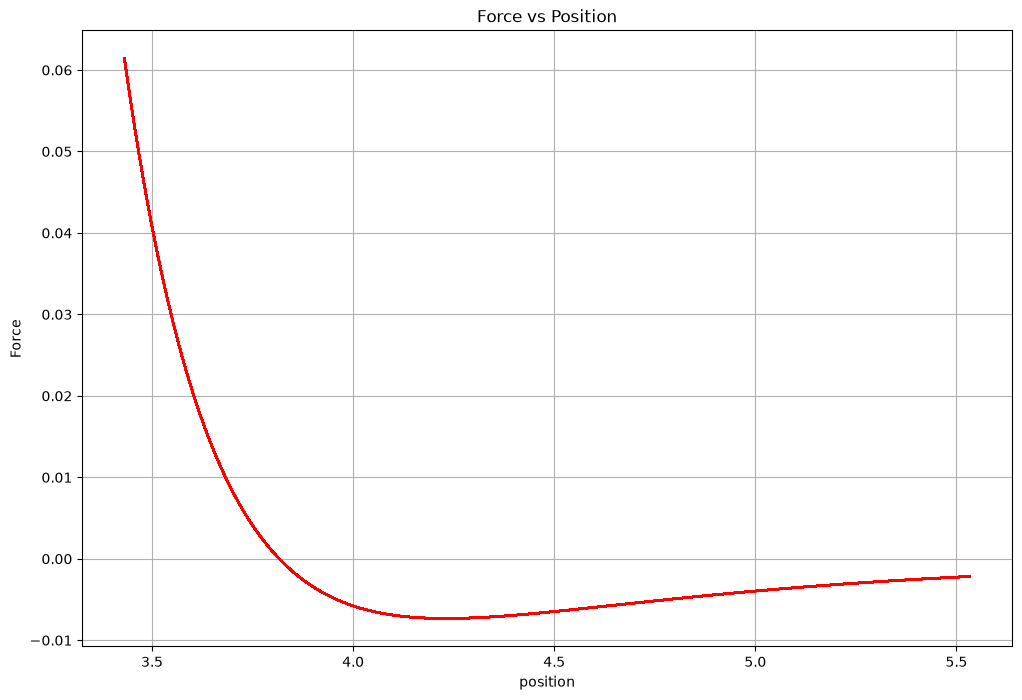

In [17]:
plt.figure(figsize=(12,8))
plt.plot(x,F, color='red')
plt.grid()
plt.title("Force vs Position")
plt.xlabel('position')
plt.ylabel('Force')
plt.show()

In [18]:
print("The force acting at the minimum of Potential Energy is ", force(min),"eV/Å")



The force acting at the minimum of Potential Energy is  7.399015465097136e-08 eV/Å


Momentum VS X

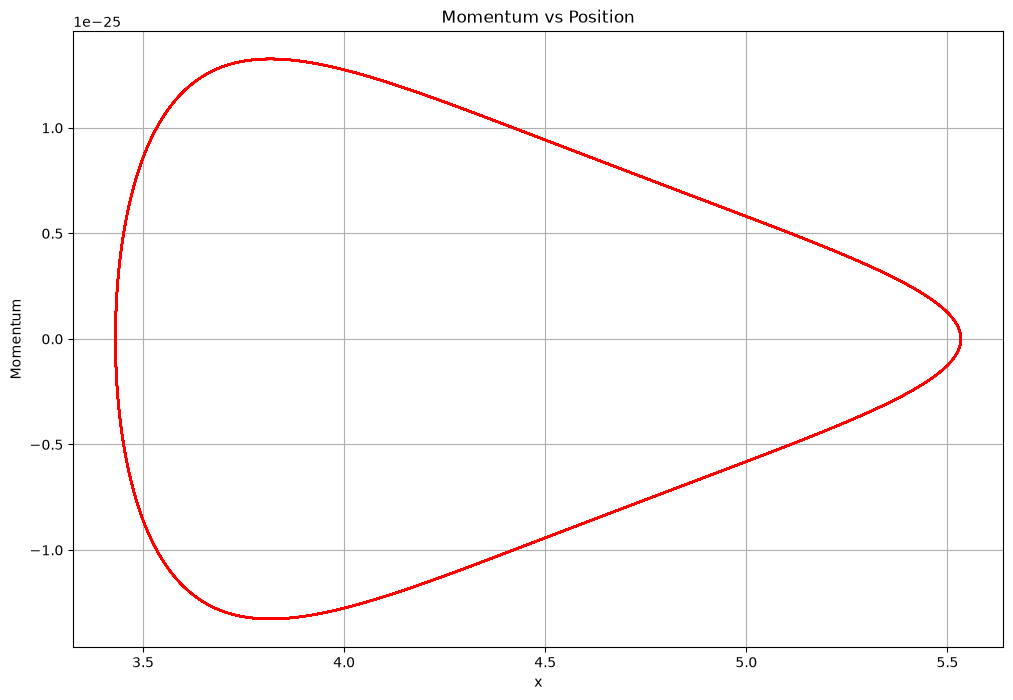

In [19]:
plt.figure(figsize=(12,8))
plt.plot(x,m0*v, color='red')
plt.grid()
plt.title('Momentum vs Position')
plt.xlabel('x')
plt.ylabel('Momentum')
plt.show()

Time Sensitivity

Although a larger time step would speed up computation, it could also result in numerical errors, energy drift, and instability. On the other hand, longer simulation times result from a smaller time step, which also improves accuracy. The system's overall energy is well-conserved, according to the "Energy vs. Time" plot, suggesting that the dt of 0.001 ps selected is suitable and offers adequate accuracy for this simulation

Stability of Oscillations

. Starting near x ~ 3.8 A - stable oscillations around the equilibrium point.
. Momentum vs. position forms an ellipse-like loop, characteristic of harmonic-like motion near the
minimum.

The oscillations become unstable when the total Energy of the system E > 0.

For a given velocity v0, we can mathematically find the minimum initial position x0 required for stable oscillations by ensuring the total energy E < 0.

The total energy is given by:[ E = KE + PE = (m v0^2)/2 + U(x0) ] where U(x0) is the Lennard-Jones potential at x0.

Setting E = 0 gives the threshold for instability:[(m v0^2)/2 + U(x0) = 0][U(x_0) = - (m v_0^2)/2]

To find the minimum x0 for a given v0, we solve for x0 such that the potential energy at x0 equals - (m v0^2)/2 .

For v0 = 2 Å/ps and m = 6.63*10^{-26} kg , and converting the kinetic energy to eV we get: [ KE = 0.008280368450278923 eV ]

Calculate U(x0) using the Lennard-Jones potential and solve for x0 numerically to find the minimum position for stability.

KE, PE, E Vs t 

In [20]:
t = np.zeros(n, dtype=float)
for i in range(n):
    t[i] = i*dt


In [21]:
K = KE(v)
E = K + U

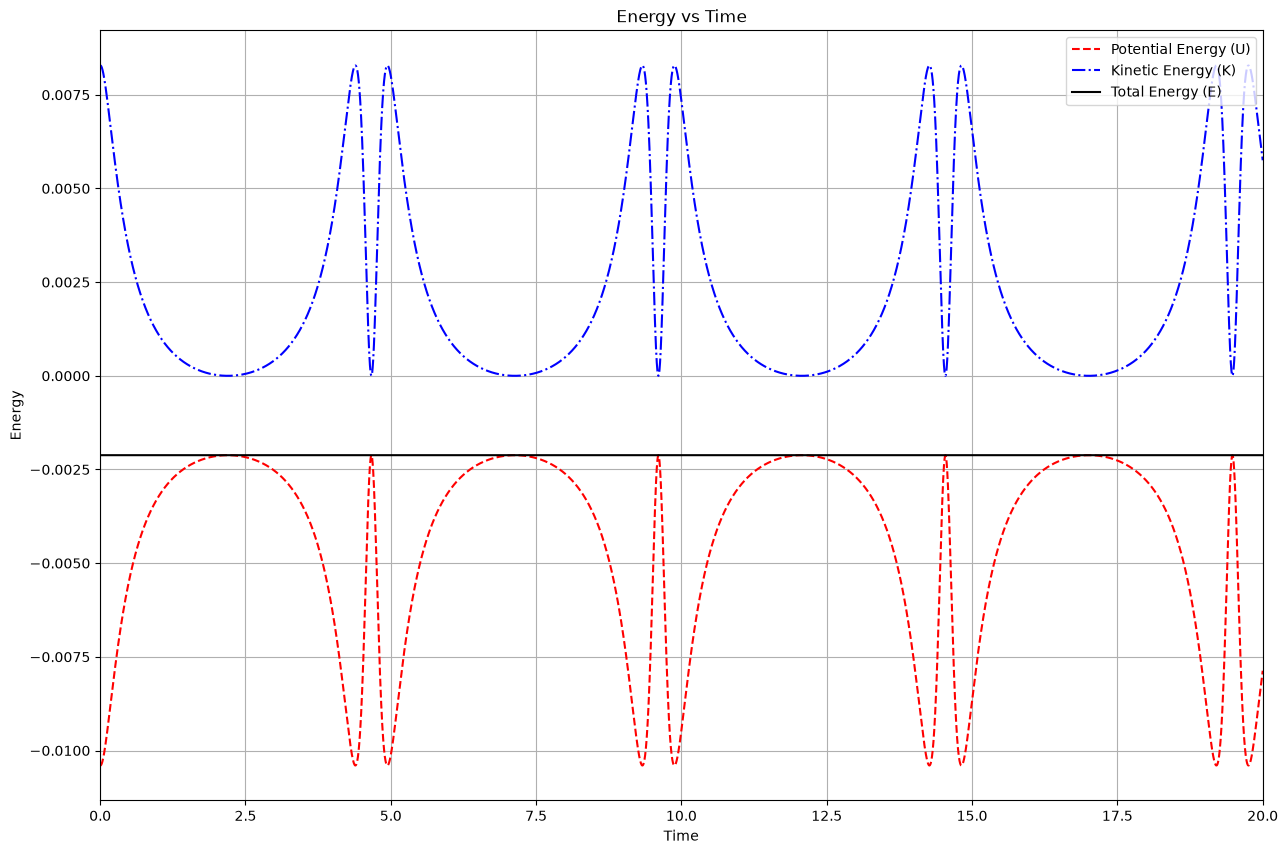

In [22]:
plt.figure(figsize=(15,10))
plt.plot(t,U, color = 'red',ls = '--')
plt.plot(t,K, color = 'blue' ,ls = '-.')
plt.plot(t,E, color = "black")
plt.grid()
plt.legend(['Potential Energy (U)', 'Kinetic Energy (K)','Total Energy (E)'], loc='upper right')
plt.xlim(0,20)
plt.title("Energy vs Time")
plt.xlabel('Time')
plt.ylabel('Energy')
plt.show()

Energy Conservation:

1.The total energy(black)should remain nearly constant that confirms the verlet algorithm conserves energy well for small dt

. Minor fluctuations are expected due to numerical rounding but should not drift significantly.

2. Energy Exchange

. As the oscillator moves, kinetic energy (blue) and potential energy (red) oscillate out of phase:

. When x is near equilibrium - KE is maximum, PE is minimum.

. At turning points - KE is minimum, PE is maximum.

In [ ]:
E_mean = np.mean(E)
fluct = (E.max() - E.min()) / abs(E_mean) * 100
print(f"Mean total energy: {E_mean:.6e} eV")
print(f"Max-min fluctuation: {E.max() - E.min():.3e} eV")
print(f"Relative fluctuation: {fluct:.4f}%")

first = np.mean(E[:n//10])
last = np.mean(E[-n//10:])
print(f"Drift (first 10% vs last 10%): {(last - first)/abs(E_mean)*100:.4f}%")

Mean total energy: -2.118226e-03 eV
Max-min fluctuation: 4.588e-07 eV
Relative fluctuation: 0.0217%
Drift (first 10% vs last 10%): 0.0000%


v0 = 1.5: max x = 4.59 Å
v0 = 2.0: max x = 5.53 Å
v0 = 2.5: max x = 115.68 Å
v0 = 3.0: max x = 203.74 Å


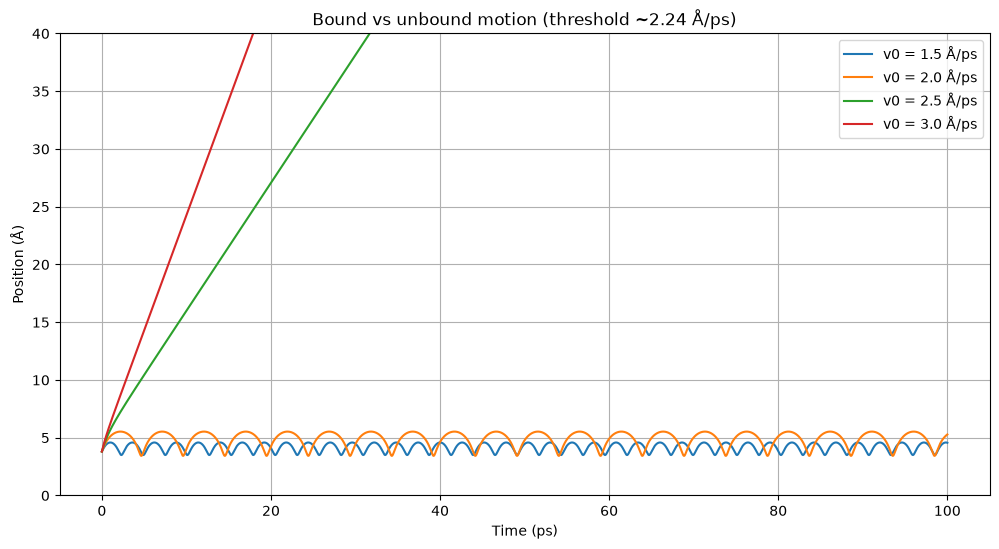

In [24]:
def simulate(v0, steps=100000):
    xs = np.zeros(steps+1)
    xs[0] = x0
    xs[1] = x0 + v0*dt
    for i in range(2, steps+1):
        xs[i] = 2*xs[i-1] + acc(xs[i-1])*dt*dt - xs[i-2]
    return xs

plt.figure(figsize=(12,6))
for v_try in [1.5, 2.0, 2.5, 3.0]:
    xs = simulate(v_try)
    plt.plot(np.arange(len(xs))*dt, xs, label=f"v0 = {v_try} Å/ps")
    print(f"v0 = {v_try}: max x = {xs.max():.2f} Å")
plt.ylim(0, 40)
plt.xlabel("Time (ps)")
plt.ylabel("Position (Å)")
plt.title("Bound vs unbound motion (threshold ~2.24 Å/ps)")
plt.legend()
plt.grid()
plt.show()